# 01 Preparación y exploración semanal de dengue en Ibagué

**Propósito:** obtener una serie semanal trazable antes de entrenar. Este piloto utiliza notificaciones del evento 210 con estados 2, 3 y 5; sus conteos no equivalen a todas las infecciones existentes. Este municipio se analiza y entrena por separado; el clima queda para etapas siguientes.

**Pregunta del modelo:** ¿Podemos predecir, a partir de los casos de dengue de las semanas anteriores y la época del año, si los casos de la próxima semana en Ibagué superarán el umbral histórico correspondiente a esa semana?

| Elemento | Información utilizada | Función |
|---|---|---|
| Predictores X | Semanas recientes y posición de la semana objetivo en el ciclo anual | Información con la que el modelo intenta anticipar el resultado |
| Umbral histórico | Misma semana epidemiológica en los cinco años anteriores | Referencia que define qué llamamos exceso |
| Etiqueta y | Conteo observado del objetivo comparado con su umbral | Respuesta que se aprende en entrenamiento y se verifica después |

El modelo posterior estimará una probabilidad de exceso, no un número exacto de casos ni un diagnóstico individual. Construir la etiqueta con datos observados de la semana objetivo no autoriza usarlos como predictores. El umbral en número de casos es distinto del umbral de probabilidad que activa una alerta.

Ejecutar las celdas en orden. Los cálculos están en `src/dengue/pipeline.py` para reutilizarlos y probarlos. No se muestran filas individuales de pacientes. Los originales permanecen intactos.

**Etapas:** extracción → auditoría → calendario → exploración → canal y etiqueta → variables de historia previa → exportación. El notebook 02 realiza el primer entrenamiento después de estas comprobaciones. Las variables representan asociaciones predictivas, no efectos causales demostrados.

## 1 Configuración y fuentes

La extracción se ejecuta antes de este notebook con `python scripts/extraer_ciudades.py --ciudad ibague`. Lee los 19 Excel, conserva archivo y fila de origen y genera una huella de las 69 columnas originales por registro. Los CSV derivados del compañero sirven como contraste; no constituyen la fuente canónica porque su calendario necesita reconstrucción.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/piloto.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from dengue.pipeline import *
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (12,4), 'font.size': 10})
SALIDA = raiz_salida(config('ibague'))
FIG = SALIDA/'reports/figures'
FIG.mkdir(parents=True, exist_ok=True)
cfg = config('ibague')
display(pd.Series(cfg, name='Configuración acordada').to_frame())

,Configuración acordada
municipio,73001
nombre_municipio,Ibagué
anio_inicial,2007
anio_final,2025
ventana_canal_anios,5
cuantil_canal,0.75
min_anios_canal,5
fin_entrenamiento,2021
fin_validacion,2023
anio_prueba,2024


In [2]:
source = SALIDA/'data/raw/ibague_original.csv'
if not source.exists():
    raise FileNotFoundError('Ejecutar primero scripts/extraer_ciudades.py --ciudad ibague')
raw = pd.read_csv(source, dtype='string', keep_default_na=False)
manifest = pd.DataFrame(json.loads((SALIDA/'data/raw/manifiesto_fuentes.json').read_text(encoding='utf-8')))
display(manifest[['archivo','filas','filas_municipio','sha256']])
print(f'Extraídos: {len(raw):,} registros; columnas: {raw.shape[1]}')
assert len(raw) == manifest.filas_municipio.sum()

,archivo,filas,filas_municipio,sha256
0,Datos_2007_210.xlsx,35074,1019,9a6e8847af35cd1be5ec494562c790830f058e49c1b783...
1,Datos_2008_210.xlsx,32793,553,e550c7ff0467a79d2ccc530d9fe3a320242b35ddee3dd4...
2,Datos_2009_210.xlsx,45345,1767,3464d6d9639bb9eef353eb184a32b2f432442c66ef2fde...
3,Datos_2010_210.xlsx,147224,6416,ad60638306d230926a1656081b83fbb02f598c97fce101...
4,Datos_2011_210.xlsx,29386,940,bd2843e0bfe30680e23788fa62dd0a882cf2c7b8fbf942...
5,Datos_2012_210.xlsx,52467,2301,353733f6b8cc91ef62b6fa3c7e459ca40be7e4b38151a0...
6,Datos_2013_210.xlsx,122441,5367,a3b98287d98053fe6b51557f920432b9be6d7ae9ef833c...
7,Datos_2014_210.xlsx,105356,3103,1078cf4fa93beaccdb683e5e3cb1a45788fbf349d92491...
8,Datos_2015_210.xlsx,95023,5056,2c0c52525f53a8c4b6d1e6ed868e2164feef7bdc453b4b...
9,Datos_2016_210.xlsx,100117,2163,08a534ef90c7eea144711713431befee23087ce63d91b3...


Extraídos: 57,321 registros; columnas: 24


## 2 Reglas de limpieza y trazabilidad

1. Eliminar solo duplicados exactos de las columnas originales, conservando el primer origen; no deduplicar por identificador aislado.
2. Conservar evento 210, país 170, departamento 76, municipio 001 y estados finales 2/3/5.
3. Parsear día/mes/año explícitamente, ISO o serial Excel; nunca inferir fechas ambiguas.
4. Usar exclusivamente inicio de síntomas; si falta o no puede parsearse, separar el registro sin sustituirlo por notificación.
5. Conservar los registros con notificación anterior a síntomas y marcar la anomalía; no utilizar FEC_NOT como requisito de inclusión. Comprobar síntomas frente a consulta como control adicional, sin inventar fechas.
6. Conservar retrasos mayores de 180 días como diagnóstico, sin recortarlos artificialmente.
7. Limitar por año epidemiológico validado, no por nombre de archivo.

El estado final y las revisiones posteriores impiden reconstruir perfectamente qué se sabía en cada corte. La evaluación inicial será retrospectiva.

**Decisión actualizada v1:** las 7.069 cronologías negativas de notificación se concentran en el archivo original de 2013. Se conservan como registros con síntomas válidos, con bandera de anomalía. El inicio de síntomas es interpretable en 160.704 de 160.709 registros, y no hay síntomas posteriores a consulta cuando ambas fechas están disponibles. Esto respalda su elección, sin garantizar que cada fecha sea verdadera. Los cinco registros sin inicio se separan. La versión anterior y sus métricas se guardaron en `data/historico/cronologia_v0/`.

In [3]:
micro, auditoria, calidad = preparar_microdatos(raw, cfg)
display(auditoria)
display(pd.Series({k:v for k,v in calidad.items() if k!='diagnostico_por_archivo'}, name='Diagnóstico').to_frame())
display(pd.DataFrame(calidad['diagnostico_por_archivo']))
display(micro.groupby('Estado_final_de_caso').size().rename('registros').to_frame())
assert micro.HUELLA_REGISTRO.is_unique
assert micro.cod_municipio.eq('73001').all()

,etapa,filas_restantes,excluidos
0,extraidos_municipio,57321,0
1,sin_duplicados_exactos_originales,57321,0
2,evento_y_ubicacion_validos,57321,0
3,estados_2_3_5,57321,0
4,inicio_sintomas_valido_sin_sustitucion,57321,0
5,dentro_ventana_epidemiologica,57319,2


,Diagnóstico
ini_sin_no_parseable,0
fec_not_no_parseable,0
sintomas_posteriores_notificacion,2195
retrasos_mayores_180,899
consecutive_repetidos_no_eliminados_por_id,8
fecha_principal,INI_SIN
porcentaje_inicio_valido,100.0
fec_con_no_parseable,3
sintomas_posteriores_consulta,0
filas_finales,57319


,ARCHIVO_ORIGEN,registros,cronologias_negativas,mayores_180,sin_inicio,pct_cronologia_negativa
0,Datos_2007_210.xlsx,1019,0,0,0,0.000000
1,Datos_2008_210.xlsx,553,0,1,0,0.000000
2,Datos_2009_210.xlsx,1767,0,2,0,0.000000
3,Datos_2010_210.xlsx,6416,0,1,0,0.000000
4,Datos_2011_210.xlsx,940,0,1,0,0.000000
5,Datos_2012_210.xlsx,2301,0,33,0,0.000000
6,Datos_2013_210.xlsx,5367,2195,810,0,40.898081
7,Datos_2014_210.xlsx,3103,0,15,0,0.000000
8,Datos_2015_210.xlsx,5056,0,10,0,0.000000
9,Datos_2016_210.xlsx,2163,0,5,0,0.000000


,registros
Estado_final_de_caso,
2,35127
3,21297
5,895


## 3 Reconstrucción del calendario epidemiológico

Se usan semanas domingo–sábado. La primera semana contiene al menos cuatro días del año (se obtiene desde el 4 de enero). Verificación de referencia INS 2025: semana 1 del 29/12/2024 al 04/01/2025 y semana 53 del 28/12/2025 al 03/01/2026. Debe contrastarse el calendario histórico si se incorporan otras convenciones o fuentes.

No se fuerza un panel de 52 semanas por año. Una semana sin registros se conserva con `n_registros=0` como hecho de extracción, pero `casos=NaN`: todavía no certificamos cero casos epidemiológicos ni completitud del reporte.

In [4]:
panel = construir_panel(micro, cfg)
display(panel.groupby('anio_epi').agg(semanas=('semana_epi','size'),
    notificaciones=('n_registros','sum'), semanas_sin_registros=('semana_con_registros',lambda x: (~x).sum())))
display(panel.loc[panel.semana_epi.eq(53), ['anio_epi','semana_epi','inicio_semana','fin_semana','n_registros']])
print('Reconciliación:', panel.n_registros.sum(), 'registros =', len(micro), 'microdatos incluidos')
assert panel.n_registros.sum() == len(micro)

,semanas,notificaciones,semanas_sin_registros
anio_epi,,,
2007,52,1000,0
2008,53,570,1
2009,52,1768,0
2010,52,6415,0
2011,52,940,0
2012,52,2301,0
2013,52,5367,0
2014,53,3103,0
2015,52,5056,0


,anio_epi,semana_epi,inicio_semana,fin_semana,n_registros
104,2008,53,2008-12-28,2009-01-03,0
417,2014,53,2014-12-28,2015-01-03,127
730,2020,53,2020-12-27,2021-01-02,9
991,2025,53,2025-12-28,2026-01-03,40


Reconciliación: 57319 registros = 57319 microdatos incluidos


## 4 Cobertura temporal por municipio

Revisamos presencia de registros por año; las semanas sin filas permanecen desconocidas.

In [5]:
cobertura = panel.groupby('anio_epi').agg(
    semanas=('semana_epi','size'), semanas_con_registros=('semana_con_registros','sum'),
    notificaciones=('n_registros','sum'))
cobertura['pct_semanas_con_registros'] = 100*cobertura.semanas_con_registros/cobertura.semanas
display(cobertura.round(2))
print('Presencia de registros no certifica cobertura completa. No imputamos ceros.')

,semanas,semanas_con_registros,notificaciones,pct_semanas_con_registros
anio_epi,,,,
2007,52,52,1000,100.00
2008,53,52,570,98.11
2009,52,52,1768,100.00
2010,52,52,6415,100.00
2011,52,52,940,100.00
2012,52,52,2301,100.00
2013,52,52,5367,100.00
2014,53,53,3103,100.00
2015,52,52,5056,100.00


Presencia de registros no certifica cobertura completa. No imputamos ceros.


## 5 Evolución histórica y cobertura

Una caída de notificaciones no demuestra por sí misma disminución de transmisión: puede combinar vigilancia, clasificación y cambios de reporte. Las cifras de 2025 deben revisarse en ese contexto. La vista histórica es descriptiva; no se utiliza para escoger variables o parámetros con el conjunto de prueba.

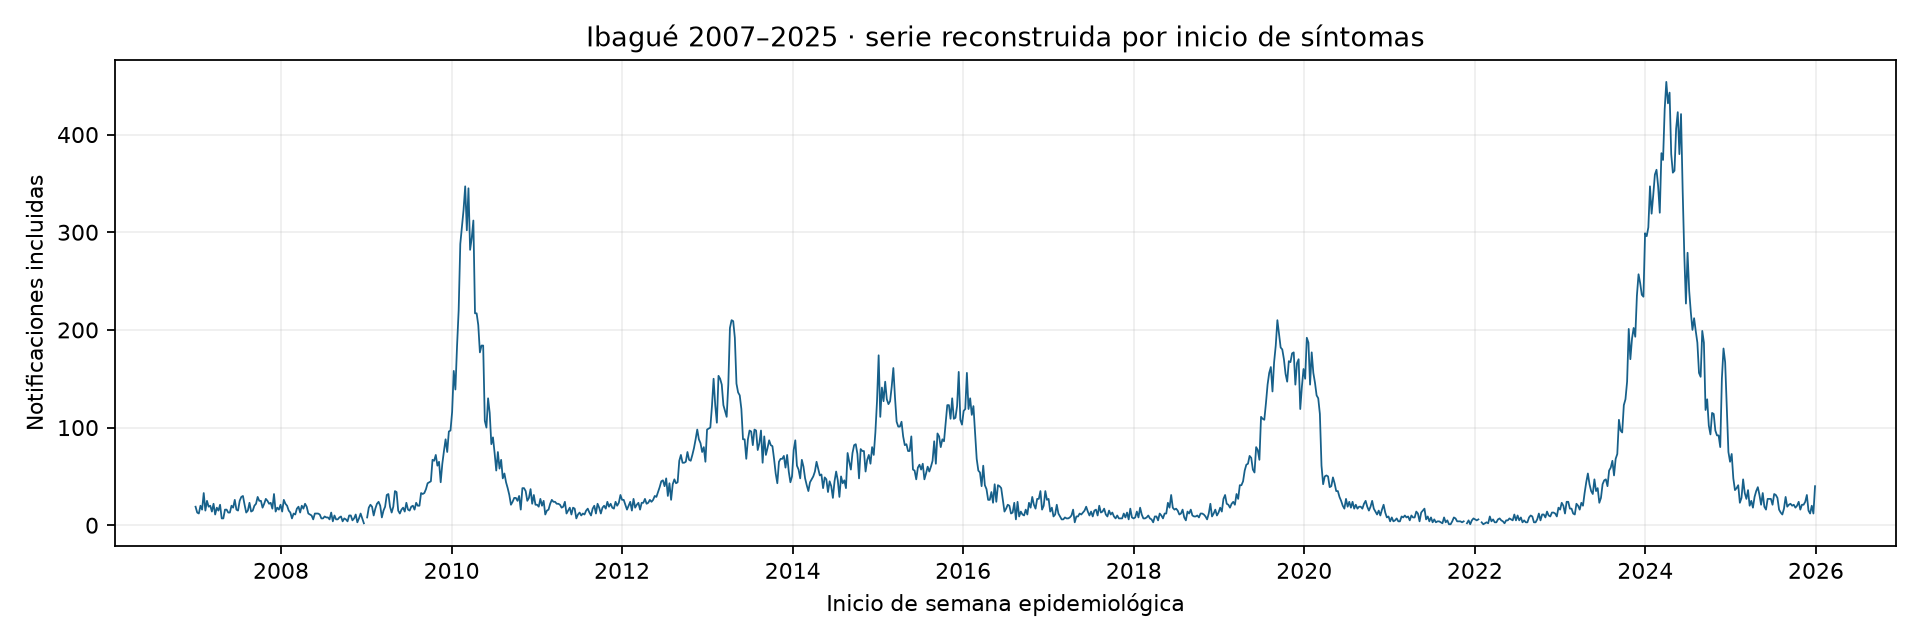

In [6]:
fig, ax = plt.subplots()
ax.plot(panel.inicio_semana, panel.casos, linewidth=0.8, color='#17608a')
ax.set(xlabel='Inicio de semana epidemiológica', ylabel='Notificaciones incluidas', title='Ibagué 2007–2025 · serie reconstruida por inicio de síntomas')
ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(FIG/'01_serie_semanal.png', dpi=160); plt.close(fig)
display(Image(filename=str(FIG/'01_serie_semanal.png')))

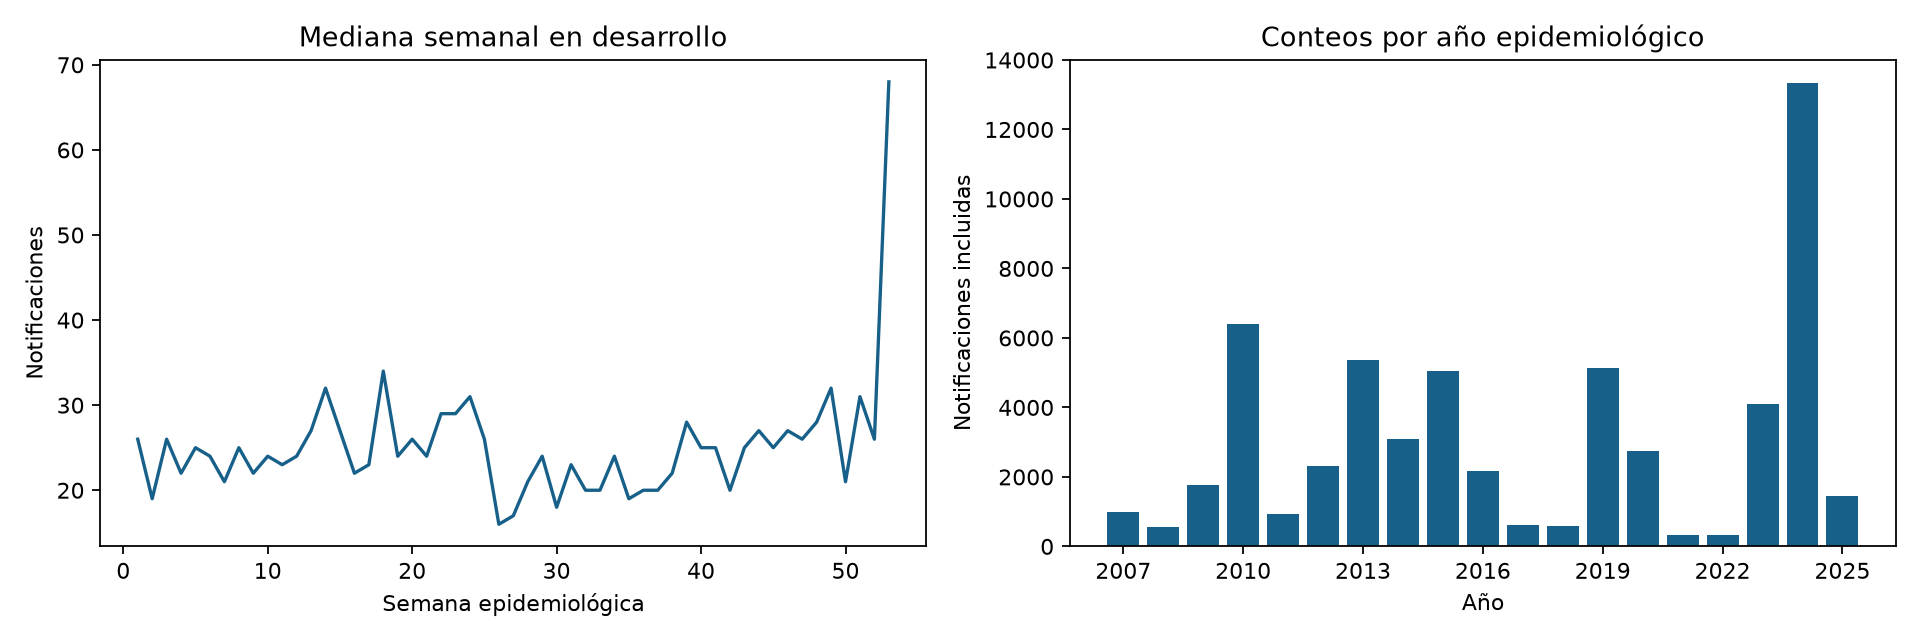

In [7]:
# Solo desarrollo para explorar estacionalidad sin seleccionar usando prueba.
desarrollo = panel.loc[panel.anio_epi<=cfg['fin_entrenamiento']]
estacional = desarrollo.groupby('semana_epi').casos.agg(['median','count'])
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(estacional.index,estacional['median'],color='#17608a')
axes[0].set(title='Mediana semanal en desarrollo',xlabel='Semana epidemiológica',ylabel='Notificaciones')
anual = panel.groupby('anio_epi').n_registros.sum()
axes[1].bar(anual.index,anual.values,color='#17608a')
axes[1].set(title='Conteos por año epidemiológico',xlabel='Año',ylabel='Notificaciones incluidas')
axes[1].set_xticks(list(range(2007,2026,3)))
fig.tight_layout();fig.savefig(FIG/'02_estacionalidad_anual.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'02_estacionalidad_anual.png')))

## 6 Retrasos y disponibilidad

Los retrasos se calculan sin convertir negativos en cero ni valores altos en 180. Las cronologías negativas de notificación se conservan como anomalías; solo los retrasos no negativos se utilizan para resumir demoras interpretables. La notificación no decide la agrupación ni la inclusión. Los conteos finales por síntomas pueden incluir notificaciones recibidas después del corte nominal: esto limita la interpretación operacional del modelo de la siguiente etapa.

,retraso_notificacion_dias
count,55124.000000
mean,13.163958
std,36.792226
min,0.000000
50%,4.000000
90%,16.000000
95%,62.000000
99%,217.770000
max,375.000000


Anomalías de notificación conservadas: 2195
Porcentaje con notificación más de 7 días después de síntomas: 19.72 (entre retrasos no negativos disponibles)


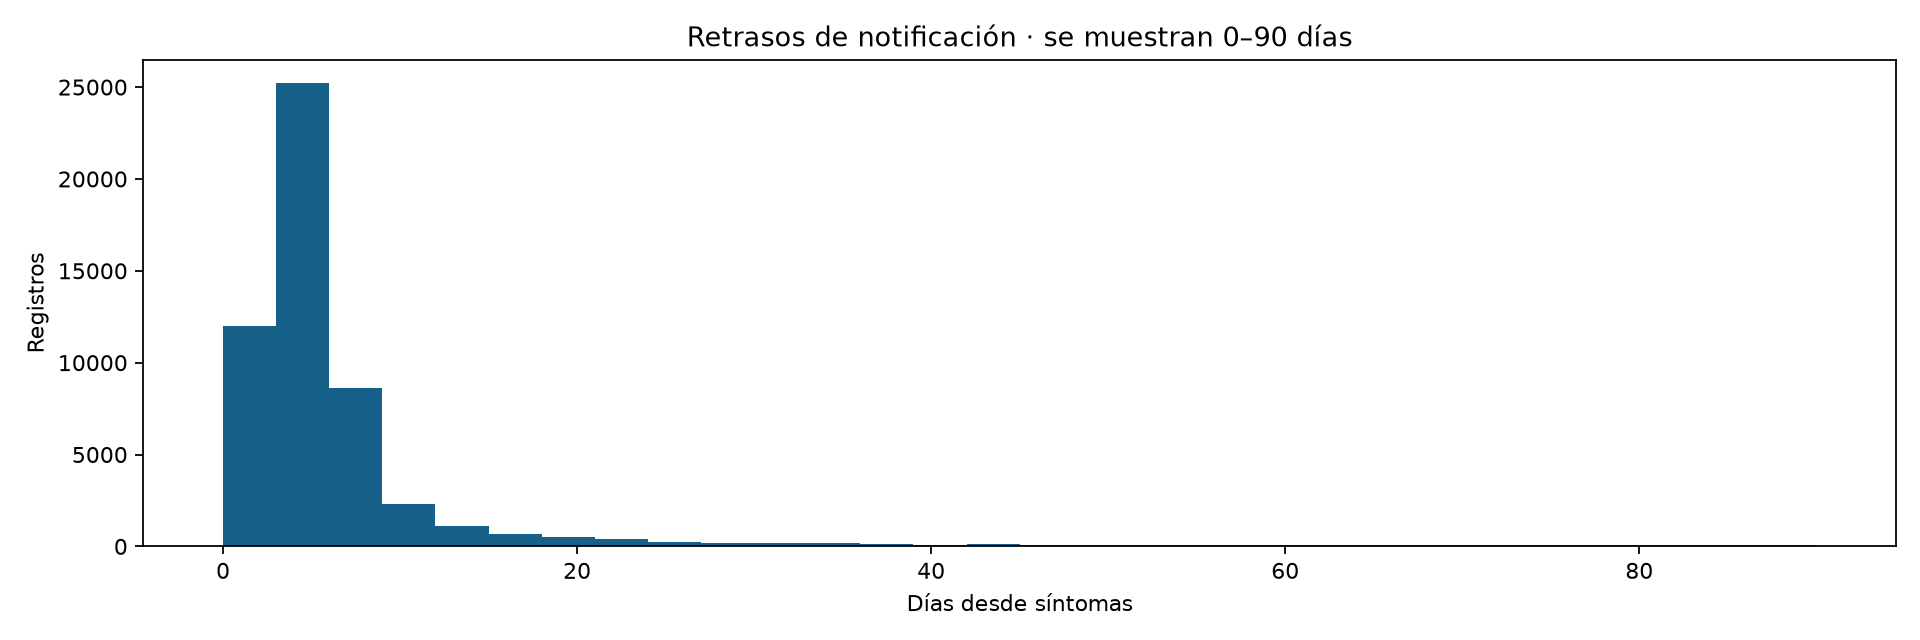

In [8]:
demora_valida = micro.retraso_notificacion_dias.where(micro.retraso_notificacion_dias.ge(0))
display(demora_valida.describe(percentiles=[.5,.9,.95,.99]).to_frame())
print('Anomalías de notificación conservadas:', int(micro.flag_notificacion_anterior_sintomas.sum()))
print('Porcentaje con notificación más de 7 días después de síntomas:',
      round(100*demora_valida.dropna().gt(7).mean(),2), '(entre retrasos no negativos disponibles)')
fig,ax=plt.subplots()
delay = demora_valida.dropna()
ax.hist(delay[delay<=90],bins=30,color='#17608a')
ax.set(title='Retrasos de notificación · se muestran 0–90 días',xlabel='Días desde síntomas',ylabel='Registros')
fig.tight_layout();fig.savefig(FIG/'03_retrasos.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'03_retrasos.png')))

## 7 Definición inicial del exceso

Para el objetivo semanal t, el umbral es el percentil 75 de los conteos de **esa misma semana epidemiológica en los cinco años anteriores**, con interpolación lineal del cuantil. Se requieren cinco valores válidos; si faltan, no se asigna etiqueta. `exceso=1` cuando el conteo observado supera estrictamente el umbral.

Esta comparación histórica define la etiqueta; no sustituye los rezagos recientes que recibirá el modelo. El umbral solo consulta años anteriores. El conteo objetivo se conoce después y permite evaluar si hubo exceso; no se incluye en X.

Es una definición operacional inicial, no una declaración oficial de epidemia ni una reproducción del canal geométrico de Bortman. Cinco observaciones por semana producen umbrales inestables; queda pendiente el análisis de sensibilidad. Los años iniciales sirven para inicializar el canal.

**Semana 53:** no depende exclusivamente de que el año sea bisiesto. Sus registros y su posición en la secuencia se conservan; si falta historia suficiente, `umbral_casos` y `exceso` quedan desconocidos, no en cero. No se combina automáticamente con la semana 52. En la semana 1 posterior, el rezago de una semana sí utiliza la semana 53 cuando existe. En nuestro panel las cuatro semanas 53 no tienen cinco antecedentes válidos dentro de su ventana, por lo que no se usan como objetivos etiquetados.

Por ejemplo, el valor `casos=30` en 2025/53 representa treinta notificaciones agrupadas en una fila semanal, no treinta semanas u observaciones de entrenamiento. La tabla siguiente permite comprobar la diferencia entre conservar el conteo y disponer de una etiqueta.

In [9]:
panel = agregar_canal(panel,cfg)
display(panel.groupby('anio_epi').agg(etiquetadas=('exceso','count'),positivas=('exceso','sum')))
display(panel.loc[panel.exceso.notna(), ['anio_epi','semana_epi','casos','n_anios_canal','umbral_casos','exceso']].head(10))
assert panel.loc[panel.exceso.notna(),'n_anios_canal'].ge(5).all()
display(panel.loc[panel.semana_epi.eq(53),
    ['anio_epi','semana_epi','inicio_semana','fin_semana','casos','n_anios_canal','umbral_casos','exceso']])

,etiquetadas,positivas
anio_epi,,
2007,0,0.0
2008,0,0.0
2009,0,0.0
2010,0,0.0
2011,0,0.0
2012,52,38.0
2013,52,44.0
2014,52,9.0
2015,52,28.0


,anio_epi,semana_epi,casos,n_anios_canal,umbral_casos,exceso
261,2012,1,26.0,5,21.0,1.0
262,2012,2,26.0,5,19.0,1.0
263,2012,3,21.0,5,27.0,0.0
264,2012,4,16.0,5,22.0,0.0
265,2012,5,20.0,5,25.0,0.0
266,2012,6,24.0,5,33.0,0.0
267,2012,7,15.0,5,22.0,0.0
268,2012,8,27.0,5,25.0,1.0
269,2012,9,18.0,5,22.0,0.0
270,2012,10,21.0,5,26.0,0.0


,anio_epi,semana_epi,inicio_semana,fin_semana,casos,n_anios_canal,umbral_casos,exceso
104,2008,53,2008-12-28,2009-01-03,NaN,0,NaN,NaN
417,2014,53,2014-12-28,2015-01-03,127.0,0,NaN,NaN
730,2020,53,2020-12-27,2021-01-02,9.0,0,NaN,NaN
991,2025,53,2025-12-28,2026-01-03,40.0,1,NaN,NaN


### 7.1 Ejemplo histórico de las dos referencias temporales

Para ilustrar la semana 20 de 2023, mostramos por separado las doce semanas inmediatamente anteriores y la semana 20 de 2018–2022. Las primeras son la fuente de rezagos y ventanas; las segundas forman el umbral. La tabla del objetivo usa su conteo observado únicamente para verificar la etiqueta: este ejemplo no es una predicción del modelo.

In [10]:
pos = panel.index[panel.anio_epi.eq(2023) & panel.semana_epi.eq(20)][0]
objetivo = panel.loc[pos]
recientes = panel.iloc[max(0,pos-12):pos][['anio_epi','semana_epi','inicio_semana','fin_semana','casos']]
historico = panel.loc[
    panel.anio_epi.between(objetivo.anio_epi-cfg['ventana_canal_anios'],objetivo.anio_epi-1)
    & panel.semana_epi.eq(objetivo.semana_epi),
    ['anio_epi','semana_epi','inicio_semana','casos']]
print('A. Historia reciente: fuente de los predictores')
display(recientes)
print('B. Misma semana de años anteriores: fuente del umbral')
display(historico)
print('C. Semana objetivo: comparación retrospectiva para obtener la etiqueta')
display(panel.loc[[pos],['anio_epi','semana_epi','casos','umbral_casos','exceso']])
assert recientes.fin_semana.max() < objetivo.inicio_semana
assert historico.anio_epi.lt(objetivo.anio_epi).all()
assert np.isclose(historico.casos.quantile(cfg['cuantil_canal']),objetivo.umbral_casos)

A. Historia reciente: fuente de los predictores


,anio_epi,semana_epi,inicio_semana,fin_semana,casos
842,2023,8,2023-02-19,2023-02-25,17.0
843,2023,9,2023-02-26,2023-03-04,12.0
844,2023,10,2023-03-05,2023-03-11,11.0
845,2023,11,2023-03-12,2023-03-18,22.0
846,2023,12,2023-03-19,2023-03-25,20.0
847,2023,13,2023-03-26,2023-04-01,16.0
848,2023,14,2023-04-02,2023-04-08,23.0
849,2023,15,2023-04-09,2023-04-15,20.0
850,2023,16,2023-04-16,2023-04-22,33.0
851,2023,17,2023-04-23,2023-04-29,44.0


B. Misma semana de años anteriores: fuente del umbral


,anio_epi,semana_epi,inicio_semana,casos
593,2018,20,2018-05-13,12.0
645,2019,20,2019-05-12,71.0
697,2020,20,2020-05-10,43.0
750,2021,20,2021-05-16,13.0
802,2022,20,2022-05-15,5.0


C. Semana objetivo: comparación retrospectiva para obtener la etiqueta


,anio_epi,semana_epi,casos,umbral_casos,exceso
854,2023,20,35.0,43.0,0.0


## 8 Variables disponibles antes de la semana objetivo

La fila t corresponde a la semana a predecir; su corte nominal es el sábado inmediatamente anterior. Se usan conteos de t−1, t−2, t−3, t−4, t−8 y t−12, media/desviación de las cuatro semanas anteriores y estacionalidad conocida del objetivo. Se exige historia completa para estas variables; no se interpolan faltantes.

La hipótesis de trabajo es que la historia reciente ayuda a anticipar el exceso relativo a ese umbral estacional. Un aumento frente a la semana anterior no significa necesariamente exceso, y puede haber exceso aun cuando el conteo esté bajando.

Se excluyen como predictores los conteos del objetivo, su etiqueta, su umbral y las características de pacientes de esa semana. El umbral se guarda para interpretar la etiqueta y construir la referencia de persistencia. Incluso los rezagos finales deben interpretarse como evaluación retrospectiva, pues el retraso de notificación impide afirmar que estuvieran completos al corte.

In [11]:
panel = agregar_features(panel)
display(panel.loc[panel.elegible_modelo,['inicio_semana','corte_prediccion',*FEATURES,'exceso']].head())
display(pd.DataFrame({'variable':FEATURES,'origen':['historia anterior']*8+['calendario conocido']*2}))
annual, summary = exportar_eda(raw,micro,auditoria,calidad,panel,cfg)
display(annual)
display(pd.Series({k:v for k,v in summary.items() if k!='diagnostico_por_archivo'},name='Resultado de preparación').to_frame())
assert not set(FEATURES).intersection({'casos','exceso','umbral_casos','casos_confirmados','hospitalizados'})
assert panel.loc[panel.elegible_modelo,FEATURES+['exceso']].notna().all().all()

,inicio_semana,corte_prediccion,lag_1,lag_2,lag_3,lag_4,lag_8,lag_12,media_4,std_4,semana_sin,semana_cos,exceso
261,2012-01-01,2011-12-31,31.0,23.0,20.0,24.0,19.0,18.0,24.50,4.654747,0.000000,1.000000,1.0
262,2012-01-08,2012-01-07,26.0,31.0,23.0,20.0,22.0,20.0,25.00,4.690416,0.120537,0.992709,1.0
263,2012-01-15,2012-01-14,26.0,26.0,31.0,23.0,18.0,17.0,26.50,3.316625,0.239316,0.970942,0.0
264,2012-01-22,2012-01-21,21.0,26.0,26.0,31.0,17.0,24.0,26.00,4.082483,0.354605,0.935016,0.0
265,2012-01-29,2012-01-28,16.0,21.0,26.0,26.0,24.0,19.0,22.25,4.787136,0.464723,0.885456,0.0


,variable,origen
0,lag_1,historia anterior
1,lag_2,historia anterior
2,lag_3,historia anterior
3,lag_4,historia anterior
4,lag_8,historia anterior
5,lag_12,historia anterior
6,media_4,historia anterior
7,std_4,historia anterior
8,semana_sin,calendario conocido
9,semana_cos,calendario conocido


,semanas,con_registros,notificaciones_incluidas,elegibles
anio_epi,,,,
2007,52,52,1000,0
2008,53,52,570,0
2009,52,52,1768,0
2010,52,52,6415,0
2011,52,52,940,0
2012,52,52,2301,52
2013,52,52,5367,52
2014,53,53,3103,52
2015,52,52,5056,52


,Resultado de preparación
ini_sin_no_parseable,0
fec_not_no_parseable,0
sintomas_posteriores_notificacion,2195
retrasos_mayores_180,899
consecutive_repetidos_no_eliminados_por_id,8
fecha_principal,INI_SIN
porcentaje_inicio_valido,100.0
fec_con_no_parseable,3
sintomas_posteriores_consulta,0
filas_finales,57319


### 8.1 Diccionario del panel y selección de campos

El panel semanal exportado tiene 28 columnas en esta versión. Solo diez son predictores y `exceso` es la respuesta. Los microdatos individuales constituyen otra tabla para auditoría. Elegir un campo como predictor no demuestra significancia estadística ni una mejora: su aporte debe comprobarse en validación temporal.

In [12]:
significados = {
    'anio_epi':'Año epidemiológico; identifica y separa bloques temporales.',
    'semana_epi':'Número de semana epidemiológica.',
    'inicio_semana':'Domingo de inicio de la semana.',
    'fin_semana':'Sábado de fin de la semana.',
    'semanas_en_anio':'52 o 53; interviene en la codificación del ciclo anual.',
    'n_registros':'Filas incluidas; cero significa ausencia de filas, no cero casos certificado.',
    'casos_confirmados':'Registros de estados finales 3 o 5.',
    'hospitalizados':'Registros con hospitalización indicada.',
    'retraso_mediana':'Mediana de retrasos de notificación no negativos disponibles.',
    'ultima_notificacion':'Última notificación entre los registros de la semana.',
    'semana_con_registros':'Indica presencia de registros, sin certificar cobertura completa.',
    'casos':'Conteo analítico; desconocido cuando no hay registros.',
    'cod_municipio':'Código de Ibagué, 73001.',
    'n_anios_canal':'Antecedentes válidos disponibles para el umbral de esa semana.',
    'umbral_casos':'P75 de la misma semana en los cinco años anteriores.',
    'exceso':'Etiqueta: 1 si casos supera el umbral, 0 en otro caso; desconocida si falta información.',
    **{f'lag_{k}':f'Conteo de {k} semana(s) antes de la semana objetivo.' for k in [1,2,3,4,8,12]},
    'media_4':'Media de las cuatro semanas anteriores, sin incluir el objetivo.',
    'std_4':'Desviación estándar de las cuatro semanas anteriores.',
    'semana_sin':'Seno de la posición del objetivo en el ciclo anual.',
    'semana_cos':'Coseno de la posición del objetivo en el ciclo anual.',
    'corte_prediccion':'Sábado anterior al objetivo; corte nominal retrospectivo.',
    'elegible_modelo':'Hay etiqueta y todas las variables predictoras disponibles.'}
assert set(significados)==set(panel.columns)
diccionario = pd.DataFrame([
    {'columna':c,'significado':significados[c],
     'uso':('Predictor X' if c in FEATURES else 'Etiqueta y' if c=='exceso'
            else 'Construcción de etiqueta' if c in ['n_anios_canal','umbral_casos']
            else 'Observación histórica' if c=='casos' else 'Identificación o auditoría')}
    for c in panel.columns])
display(diccionario)
print(f'Panel: {panel.shape[0]} filas, {panel.shape[1]} columnas; X: {len(FEATURES)} predictores; y: exceso.')
diccionario.to_csv(SALIDA/'reports/tables/diccionario_panel_semanal.csv',index=False)

,columna,significado,uso
0,anio_epi,Año epidemiológico; identifica y separa bloque...,Identificación o auditoría
1,semana_epi,Número de semana epidemiológica.,Identificación o auditoría
2,inicio_semana,Domingo de inicio de la semana.,Identificación o auditoría
3,fin_semana,Sábado de fin de la semana.,Identificación o auditoría
4,semanas_en_anio,52 o 53; interviene en la codificación del cic...,Identificación o auditoría
5,n_registros,Filas incluidas; cero significa ausencia de fi...,Identificación o auditoría
6,casos_confirmados,Registros de estados finales 3 o 5.,Identificación o auditoría
7,hospitalizados,Registros con hospitalización indicada.,Identificación o auditoría
8,retraso_mediana,Mediana de retrasos de notificación no negativ...,Identificación o auditoría
9,ultima_notificacion,Última notificación entre los registros de la ...,Identificación o auditoría


Panel: 992 filas, 28 columnas; X: 10 predictores; y: exceso.


## 9 Cierre de la fase exploratoria y siguiente paso

Se exportaron auditoría, manifiesto de fuentes, microdatos locales, panel completo y figuras. La suma se reconcilia después de exclusiones explícitas. Se conservan semanas sin registros como desconocidas y la semana 53 sin eliminaciones artificiales.

**Siguiente notebook:** regresión logística regularizada, entrenamiento hasta 2021, validación 2022–2023, prueba 2024 y evaluación adicional 2025. No se ajusta el modelo con las métricas de prueba. Pendientes: revisión del caso/fecha con el experto, cobertura externa, sensibilidad del canal, simulación con disponibilidad real, clima y comparación entre municipios.

Referencias: [calendario INS 2025](https://portalsivigila.ins.gov.co/Documentos%20compartidos/Calendario%202025.pdf) y [Umaña et al. 2026](https://publichealth.jmir.org/2026/1/e79914).